In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score

In [18]:
df = pd.read_csv('FAOSTAT_Egypt_Agriculture_Raw.csv')
print(df.shape)
df.head()

(7978, 15)


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
0,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",1990,1990,ha,21500.0,E,Estimated value,NaN
1,QCL,Crops and livestock products,818,Egypt,5412,Yield,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",1990,1990,kg/ha,837.2,E,Estimated value,NaN
2,QCL,Crops and livestock products,818,Egypt,5510,Production,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",1990,1990,t,18000.0,E,Estimated value,NaN
3,QCL,Crops and livestock products,818,Egypt,5312,Area harvested,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",1991,1991,ha,20000.0,E,Estimated value,NaN
4,QCL,Crops and livestock products,818,Egypt,5412,Yield,1654.0,"Anise, badian, coriander, cumin, caraway, fenn...",1991,1991,kg/ha,750.0,E,Estimated value,NaN


In [19]:
data = df[['Element', 'Item', 'Year', 'Value']]
print(data.isnull().sum())
data = data.dropna()
print("Duplicates:", data.duplicated().sum())

Element     0
Item        0
Year        0
Value      40
dtype: int64
Duplicates: 0


In [20]:
data.dropna(subset=['Value'], inplace=True)

In [21]:
data.isnull().sum()

,0
Element,0
Item,0
Year,0
Value,0


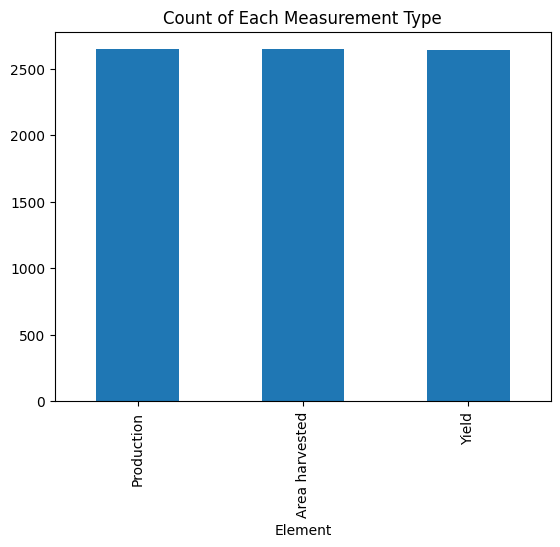

In [22]:
data['Element'].value_counts().plot(kind='bar', title='Count of Each Measurement Type')
plt.show()

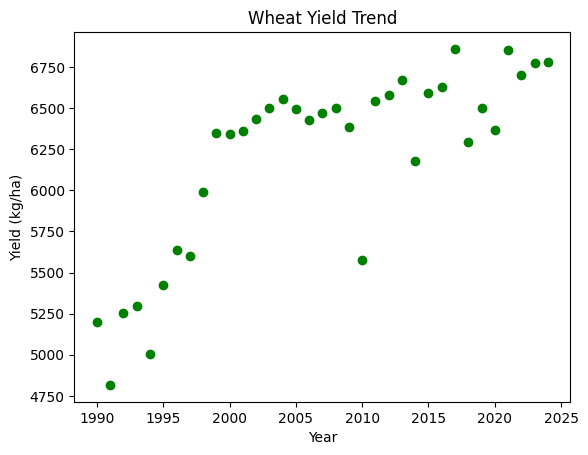

In [23]:
yield_data = data[data['Element'] == 'Yield'].copy()
wheat = yield_data[yield_data['Item'] == 'Wheat']
plt.scatter(wheat['Year'], wheat['Value'], color='green')
plt.title('Wheat Yield Trend')
plt.xlabel('Year')
plt.ylabel('Yield (kg/ha)')
plt.show()

In [24]:
yield_data = yield_data.sort_values(['Item', 'Year'])
g = yield_data.groupby('Item')['Value']
yield_data['lag1'] = g.shift(1)
yield_data['lag2'] = g.shift(2)
yield_data['lag3'] = g.shift(3)
yield_data['mean3'] = (yield_data['lag1'] + yield_data['lag2'] + yield_data['lag3']) / 3
yield_data = yield_data.dropna()

In [25]:
model_data = pd.get_dummies(yield_data[['Item', 'Year', 'lag1', 'lag2', 'mean3', 'Value']], columns=['Item'], dtype=int, drop_first=True)
X = model_data.drop('Value', axis=1)
y = model_data['Value']
train = X['Year'] <= 2015
X_train, X_test = X[train].copy(), X[~train].copy()
y_train, y_test = y[train], y[~train]
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Train rows: 1736 | Test rows: 676


In [26]:
num_cols = ['Year', 'lag1', 'lag2', 'mean3']
scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

In [27]:
def evaluate(name, y_true, y_pred):
    return {'Model': name,
            'R2': r2_score(y_true, y_pred),
            'MAE': mean_absolute_error(y_true, y_pred),
            'MAPE %': (abs(y_true - y_pred) / y_true).mean() * 100}

Lr = LinearRegression().fit(X_train_s, y_train)
Rf = RandomForestRegressor(random_state=42).fit(X_train_s, y_train)

results = pd.DataFrame([evaluate('Naive (last year)', y_test, X_test['lag1']),
                        evaluate('Linear Regression', y_test, Lr.predict(X_test_s)),
                        evaluate('Random Forest', y_test, Rf.predict(X_test_s))]).round(3)
results

,Model,R2,MAE,MAPE %
0,Naive (last year),0.969,983.630,6.380
1,Linear Regression,0.975,1180.374,13.549
2,Random Forest,0.975,1165.243,10.083


In [28]:
risk = yield_data[['Year', 'Value', 'lag1', 'lag2', 'lag3', 'mean3']].copy()
risk['ch1'] = risk['lag1'] / risk['lag2'] - 1
risk['ch2'] = risk['lag2'] / risk['lag3'] - 1
risk['gap'] = risk['lag1'] / risk['mean3'] - 1
risk['drop'] = ((risk['Value'] / risk['lag1'] - 1) < -0.10).astype(int)
risk = risk.replace([np.inf, -np.inf], np.nan).dropna()
features = ['ch1', 'ch2', 'gap']
r_train = risk['Year'] <= 2015
Xr_train, Xr_test = risk.loc[r_train, features], risk.loc[~r_train, features]
yr_train, yr_test = risk.loc[r_train, 'drop'], risk.loc[~r_train, 'drop']
scaler_r = StandardScaler()
Xr_train_s = pd.DataFrame(scaler_r.fit_transform(Xr_train), columns=features)
Xr_test_s = pd.DataFrame(scaler_r.transform(Xr_test), columns=features)

In [29]:
Lr_risk = LogisticRegression().fit(Xr_train_s, yr_train)
risk_prob = Lr_risk.predict_proba(Xr_test_s)[:, 1]
top = np.argsort(-risk_prob)[:int(len(risk_prob) * 0.10)]
print("AUC:", round(roc_auc_score(yr_test, risk_prob), 3))
print("Actual drop rate overall   :", round(yr_test.mean() * 100, 1), "%")
print("Drop rate in riskiest 10%  :", round(yr_test.values[top].mean() * 100, 1), "%")

AUC: 0.597
Actual drop rate overall   : 8.6 %
Drop rate in riskiest 10%  : 22.4 %


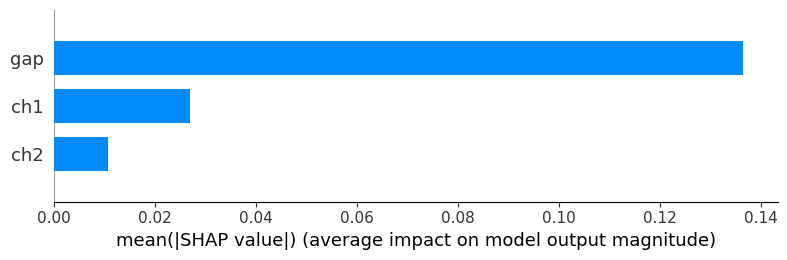

In [30]:
masker = shap.maskers.Independent(Xr_train_s, max_samples=len(Xr_train_s))
explainer = shap.LinearExplainer(Lr_risk, masker)
shap.summary_plot(explainer.shap_values(Xr_test_s), Xr_test_s, plot_type='bar')